Here , instead of the classical ReLu function we use a new function called the SWISH function
It is simply defined as SWISH(x)=x*sigmoid(x) where sigmoid(x)=1/(1+e^(-x))

This is especially useful for datasets having negative output values , as the classical ReLu function simply discards negative values , which results in a fair amount of
the values of the input x being set to 0 after applying the activation function.With a derivative=0 , the weight is not updated , and if the weight is already 0 it can
result in dead neurons.

The SWISH function fixes that problem.

Only the activation function has been changed , the rest of the code is the same as for the original Task4.0 code.

SWISH displays a higher test accuracy (95 in original , compared to 96.2 here)
The loss decreases in an irregular manner , but it does decrease to a minimum at the end.

In [7]:
import numpy as np
import cv2
import os
import zipfile
import matplotlib.pyplot as plt
from LogisticRegression import sigmoid #Logistic regression class file which was made for Task 2

In [8]:
def unzip(zip_path):
    with zipfile.ZipFile(zip_path,'r') as z:
        z.extractall()

unzip("Train.zip")
unzip("Test.zip")

In [9]:
IMG_SIZE = 64

def load_dataset(folder):

    X = []
    y = []

    classes = sorted(os.listdir(folder))

    for label,cls in enumerate(classes):

        class_path = os.path.join(folder,cls)

        if not os.path.isdir(class_path):
            continue

        for file in os.listdir(class_path):

            path = os.path.join(class_path,file)

            img = cv2.imread(path)

            if img is None:
                continue

            img = cv2.resize(img,(IMG_SIZE,IMG_SIZE))
            img = img/255.0

            X.append(img.flatten())
            y.append(label)

    return np.array(X),np.array(y),classes

In [10]:
X_train,y_train,classes = load_dataset("Train")
X_test,y_test,_ = load_dataset("Test")

print("Train:",X_train.shape)
print("Test:",X_test.shape)

Train: (4000, 12288)
Test: (1000, 12288)


In [11]:
def one_hot(y,num_classes):

    out = np.zeros((len(y),num_classes))
    out[np.arange(len(y)),y] = 1

    return out

num_classes = len(classes)

y_train_oh = one_hot(y_train,num_classes)
print(y_train_oh)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [12]:
np.random.seed(0)

input_size = X_train.shape[1]
h1 = 256
h2 = 128
output = num_classes

W1 = np.random.randn(input_size,h1)*np.sqrt(2/input_size)
b1 = np.zeros((1,h1))

W2 = np.random.randn(h1,h2)*np.sqrt(2/h1)
b2 = np.zeros((1,h2))

W3 = np.random.randn(h2,output)*np.sqrt(2/h2)
b3 = np.zeros((1,output))

In [18]:
def swish(x):
    return x*sigmoid(x)

def swish_deriv(x):
    return sigmoid(x)*(1-sigmoid(x)+x)

def softmax(x):

    exp = np.exp(x-np.max(x,axis=1,keepdims=True))
    return exp/np.sum(exp,axis=1,keepdims=True)

In [19]:

def forward(X):
    z_1 = X @ W1 + b1
    a_1 = swish(z_1)

    z_2 = a_1 @ W2 + b2
    a_2 = swish(z_2)

    z_3 = a_2 @ W3 + b3
    a_3 = softmax(z_3)

    cache = (z_1, a_1, z_2, a_2, z_3, a_3)

    return a_3, cache

In [20]:
def loss(Y,Yhat):

    m = Y.shape[0]

    return -np.sum(Y*np.log(Yhat+1e-9))/m

In [21]:
def backward(X,Y,cache):

    z_1,a_1,z_2,a_2,z_3,a_3 = cache
    m = X.shape[0]

    dz_3 = a_3-Y
    dw_3 = a_2.T@dz_3/m
    db3 = np.sum(dz_3,axis=0,keepdims=True)/m

    da_2 = dz_3@W3.T
    dz_2 = da_2*swish_deriv(z_2)

    dw_2 = a_1.T@dz_2/m
    db2 = np.sum(dz_2,axis=0,keepdims=True)/m

    da_1 = dz_2@W2.T
    dz_1 = da_1*swish_deriv(z_1)

    dw_1 = X.T@dz_1/m
    db1 = np.sum(dz_1,axis=0,keepdims=True)/m

    return dw_1,db1,dw_2,db2,dw_3,db3

In [22]:
lr = 0.001
epochs = 40
batch_size = 32

losses = []

for epoch in range(epochs):

    perm = np.random.permutation(len(X_train))

    X_train = X_train[perm]
    y_train_oh = y_train_oh[perm]

    for i in range(0,len(X_train),batch_size):

        Xb = X_train[i:i+batch_size]
        Yb = y_train_oh[i:i+batch_size]

        yhat,cache = forward(Xb)

        dW1,db1,dW2,db2,dW3,db3 = backward(Xb,Yb,cache)

        W1[:] -= lr*dW1
        b1[:] -= lr*db1

        W2[:] -= lr*dW2
        b2[:] -= lr*db2

        W3[:] -= lr*dW3
        b3[:] -= lr*db3

    pred,_ = forward(X_train)
    l = loss(y_train_oh,pred)

    losses.append(l)

    print("Epoch",epoch,"Loss",l)

Epoch 0 Loss 1.3762772236268552
Epoch 1 Loss 1.0402661927939658
Epoch 2 Loss 0.6197913426020338
Epoch 3 Loss 0.3416710183424885
Epoch 4 Loss 0.30193447797456613
Epoch 5 Loss 0.8649584096711171
Epoch 6 Loss 0.22802671309504602
Epoch 7 Loss 0.15861719116040734
Epoch 8 Loss 0.18770940315746704
Epoch 9 Loss 0.17338847363143287
Epoch 10 Loss 0.27793773873628774
Epoch 11 Loss 0.12831653542092264
Epoch 12 Loss 0.3466236819580023
Epoch 13 Loss 0.11488358536501872
Epoch 14 Loss 0.13275148525585076
Epoch 15 Loss 0.11264789421025627
Epoch 16 Loss 0.13762965289025178
Epoch 17 Loss 0.11290614358015166
Epoch 18 Loss 0.11312855823133271
Epoch 19 Loss 0.10949371077005689
Epoch 20 Loss 0.11884778478635141
Epoch 21 Loss 0.1160423527434725
Epoch 22 Loss 0.13522623365932662
Epoch 23 Loss 0.13136031892656194
Epoch 24 Loss 0.11193547131571045
Epoch 25 Loss 0.12712074489361821
Epoch 26 Loss 0.16364735992263268
Epoch 27 Loss 0.11328561417335331
Epoch 28 Loss 0.1302737934092162
Epoch 29 Loss 0.1060033714394456

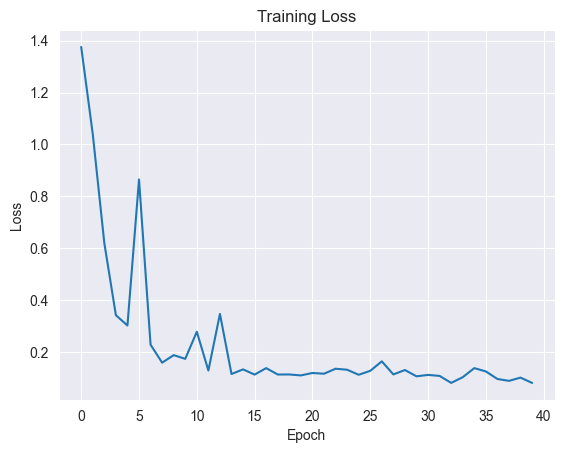

In [23]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

In [24]:
def predict(X):

    p,_ = forward(X)
    return np.argmax(p,axis=1)

In [25]:
y_pred = predict(X_test)

accuracy = np.mean(y_pred==y_test)

print("Test Accuracy:",accuracy)

Test Accuracy: 0.962


In [26]:
num_classes = len(classes)

cm = np.zeros((num_classes,num_classes))

for t,p in zip(y_test,y_pred):
    cm[t][p]+=1

print("Confusion Matrix")
print(cm)

Confusion Matrix
[[200.   0.   0.   0.   0.]
 [  0. 197.   0.   3.   0.]
 [  1.   0. 190.   2.   7.]
 [  1.  16.   0. 183.   0.]
 [  0.   0.   8.   0. 192.]]
